# 02 — DQN on CartPole-v1

Inspects the network and analyses the saved DQN logs (seeds 0–4).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.float_format", "{:.3f}".format)
RESULTS = ROOT / "results"

In [2]:
import yaml, torch
from src.agents.dqn import DQNAgent
cfg = yaml.safe_load((ROOT / "configs" / "cartpole.yaml").read_text())
print(yaml.safe_dump(cfg["dqn"]))
agent = DQNAgent(4, 2, np.random.default_rng(0), hidden_sizes=tuple(cfg["dqn"]["hidden_sizes"]))
print(agent.online_network)
print("parameters:", agent.diagnostics()["n_parameters"])

batch_size: 64
buffer_size: 50000
epsilon:
  duration: 20000
  end: 0.05
  start: 1.0
hidden_sizes:
- 128
- 128
learning_rate: 0.0001
learning_starts: 1000
max_grad_norm: 10.0
target_update_interval: 1000
train_frequency: 1



QNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
parameters: 17410


## Per-seed results

In [3]:
per_run = pd.read_csv(RESULTS / "comparison" / "per_run_metrics.csv")
per_run[per_run.run_name == "dqn"][["seed", "final_eval_mean_100", "final_eval_std_100", "steps_to_threshold",
    "best_checkpoint_mean_10", "best_checkpoint_step", "last_checkpoint_mean_10", "post_success_drops_gt100", "train_time_s"]]

,seed,final_eval_mean_100,final_eval_std_100,steps_to_threshold,best_checkpoint_mean_10,best_checkpoint_step,last_checkpoint_mean_10,post_success_drops_gt100,train_time_s
0,0,429.700,113.504,NaN,473.700,200000,473.700,0,355.233
1,1,500.000,0.000,5000.000,500.000,170000,500.000,1,342.100
2,2,500.000,0.000,105000.000,500.000,105000,500.000,3,348.544
3,3,500.000,0.000,130000.000,500.000,130000,500.000,1,364.643
4,4,24.180,16.968,140000.000,500.000,140000,22.300,2,347.839


## Evaluation curve of each seed (stability)

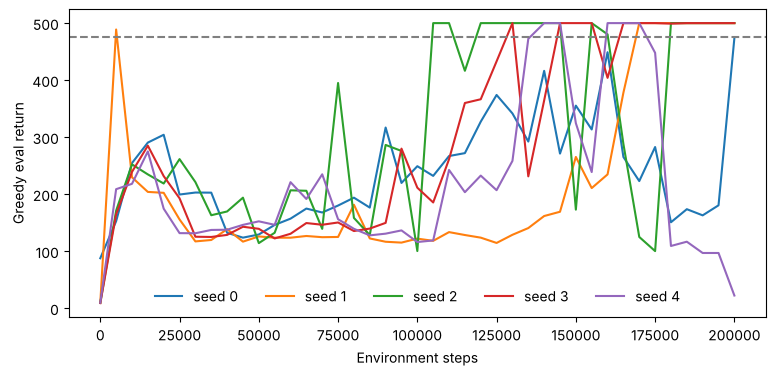

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for s in range(5):
    ev = pd.read_csv(RESULTS / "dqn" / "logs" / "dqn" / f"seed_{s}" / "evals.csv")
    ax.plot(ev.step, ev.mean_return, linewidth=1.5, label=f"seed {s}")
ax.axhline(475, ls="--", c="gray"); ax.set_xlabel("Environment steps"); ax.set_ylabel("Greedy eval return")
ax.legend(frameon=False, ncol=5); plt.show()

## Loss and exploration

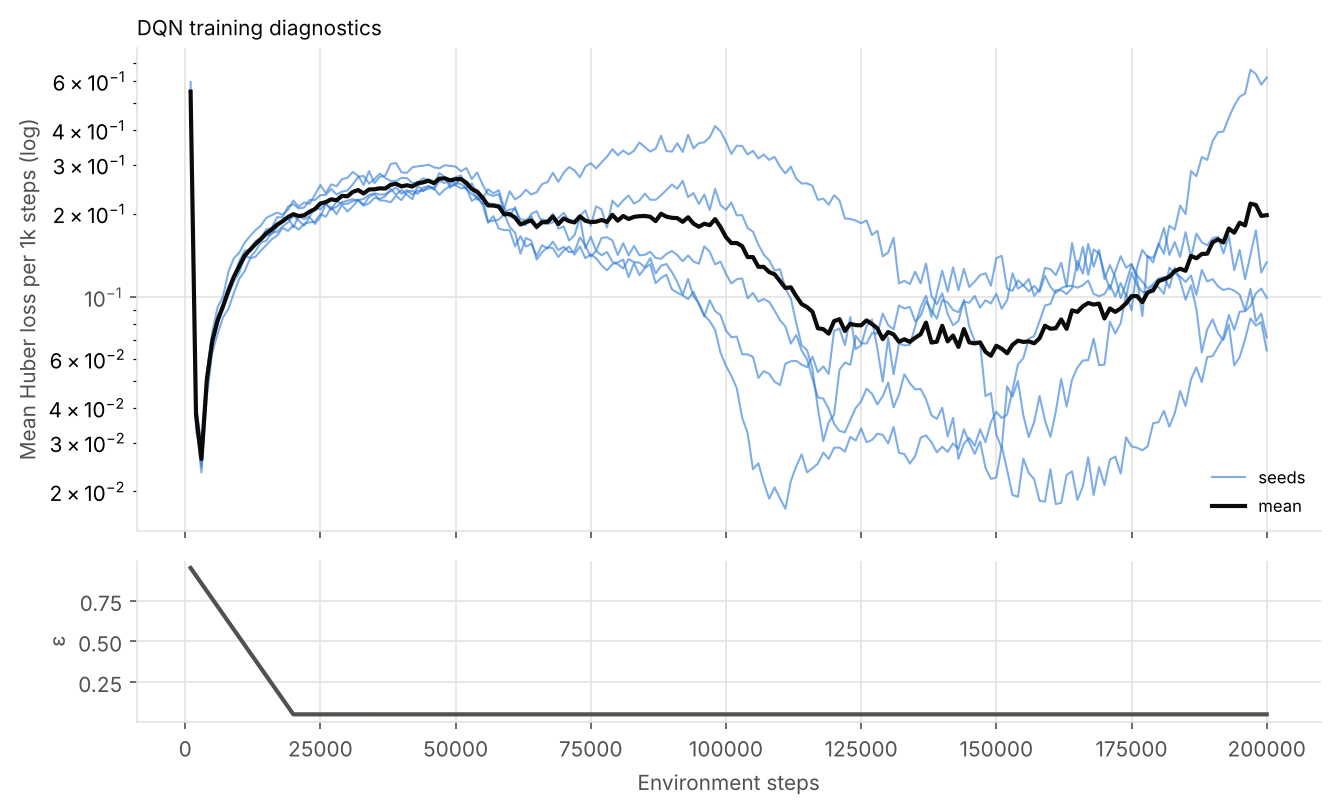

In [5]:
display(Image(RESULTS / "dqn" / "figures" / "loss_and_epsilon.png"))

## Load a saved model and evaluate it greedily

In [6]:
from src.utils.evaluation import evaluate_policy
agent.online_network.load_state_dict(torch.load(RESULTS / "dqn" / "models" / "dqn" / "seed_0.pt"))
rets = evaluate_policy(agent, "CartPole-v1", 10, base_seed=123_456)
print("10 fresh greedy episodes:", rets, "mean", rets.mean())

10 fresh greedy episodes: [214. 282. 500. 500. 500. 500. 500. 500. 500. 251.] mean 424.7
